Accuracy: 0.7333333333333333

Confusion Matrix:
[[10  0  0]
 [ 0  6  4]
 [ 0  4  6]]


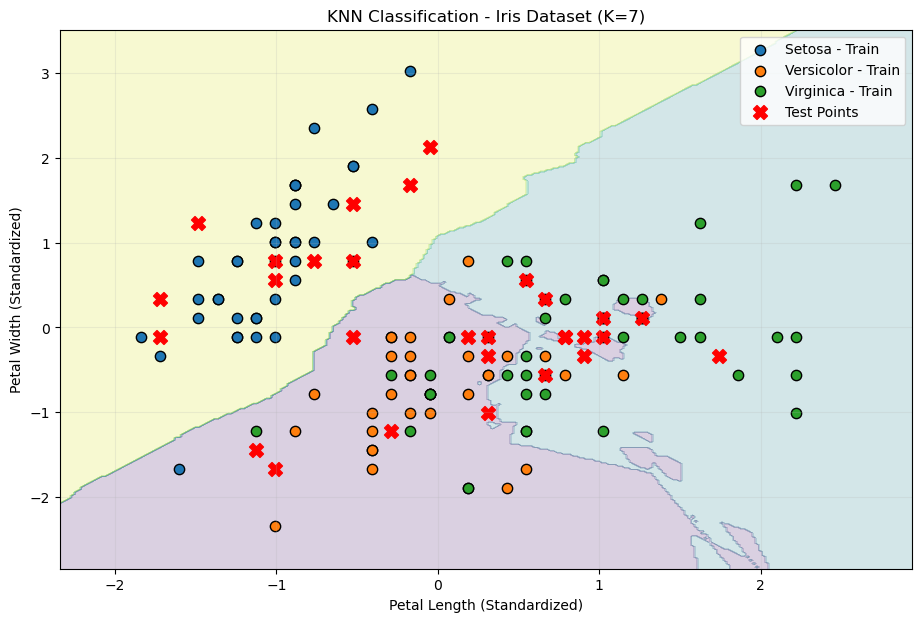

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

# 1. Read Dataset
df = pd.read_csv("data/iris.csv")

# 2. Define Feature Groups
features = {
    "Sepal": ["sepal.length", "sepal.width"],
    "Petal": ["petal.length", "petal.width"]
}

results = {}

# 3. Run KNN for Both Groups
for name, columns in features.items():

    print("\n==========================")
    print(name, "Classification")
    print("==========================")

    # Select X and Y
    X = df[columns]
    y = df["variety"]

    # Split Data
    X_train, X_test, y_train, y_test = train_test_split(
        X, y,
        test_size=0.2,
        random_state=42,
        stratify=y
    )

    # Standardization
    scaler = StandardScaler()
    
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    ks=15
    kp=3
    # Create KNN Model
    k_values = {
    "Sepal": ks,
    "Petal": kp
    }

    model = KNeighborsClassifier(
    n_neighbors=k_values[name]
    )

    # Train
    model.fit(X_train_scaled, y_train)

    # Predict
    y_pred = model.predict(X_test_scaled)

    # Accuracy
    accuracy = accuracy_score(y_test, y_pred)

    results[name] = accuracy

    print("Accuracy:", round(accuracy * 100, 2), "%")

    print("\nConfusion Matrix:")
    print(confusion_matrix(y_test, y_pred))

    # 4. Create Mesh Grid
    x_min = X_train_scaled[:, 0].min() - 0.5
    x_max = X_train_scaled[:, 0].max() + 0.5

    y_min = X_train_scaled[:, 1].min() - 0.5
    y_max = X_train_scaled[:, 1].max() + 0.5

    xx, yy = np.meshgrid(
        np.arange(x_min, x_max, 0.02),
        np.arange(y_min, y_max, 0.02)
    )

    # Predict Grid Points
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()])

    # Convert Classes to Numbers
    class_names = model.classes_
    Z = pd.Categorical(
        Z,
        categories=class_names
    ).codes.reshape(xx.shape)

    # 5. Plot
    plt.figure(figsize=(10, 7))

    plt.contourf(
        xx, yy, Z,
        alpha=0.4,
        cmap="viridis"
    )

    # Plot Training Points
    for flower in class_names:

        mask = y_train.to_numpy() == flower

        plt.scatter(
            X_train_scaled[mask, 0],
            X_train_scaled[mask, 1],
            label=f"{flower} - Train",
            s=55,
            edgecolors="black"
        )

    # Plot Test Points
    plt.scatter(
        X_test_scaled[:, 0],
        X_test_scaled[:, 1],
        marker="X",
        color="red",
        s=100,
        label="Test Points"
    )

    plt.xlabel(columns[0] + " (Standardized)")
    plt.ylabel(columns[1] + " (Standardized)")

    plt.title(
    f"KNN Classification - {name} (K={k_values[name]})\n"
    f"Accuracy: {accuracy * 100:.2f}%"
    )

    plt.legend()
    plt.grid(alpha=0.2)
    plt.show()


# 6. Compare Results
print("\n========== FINAL COMPARISON ==========")

for name, accuracy in results.items():
    print(f"{name} Accuracy: {accuracy * 100:.2f}%")

if results["Sepal"] > results["Petal"]:
    print("\nSepal has better accuracy.")

elif results["Petal"] > results["Sepal"]:
    print("\nPetal has better accuracy.")

else:
    print("\nBoth models have equal accuracy.")
